# Stage 3: visual walkthrough

This notebook shows the **work completed so far**: the train/validation score-only baseline, a real footage-quality inspection, and a synthetic ResNet-18 + regression-head smoke test. **The real-video model is blocked** until the scored cow can be localized and walking visibility reviewed. Nothing here trains on the Sydney video or evaluates the held-out test set.

**Use a local Python kernel** with the dependencies from `ml/requirements-local.txt`, plus `matplotlib` and `ipykernel`. The project environment is `ml/.venv/bin/python` (absolute path: `/Users/sam/Documents/GitHub/holycow/ml/.venv/bin/python`). In VS Code, select it as the notebook kernel, then **Run All**. If it is not listed, choose **Select Another Kernel → Python Environments → Enter interpreter path**. All raw data and outputs remain local and ignored by Git.

The videos, scores, and existing baseline outputs must be present in `ml/data/` and `ml/outputs/`; the notebook prints a useful error if they are missing. This is a research demonstration, not a veterinary diagnostic system.

In [1]:
from pathlib import Path
import sys, os, csv, json, hashlib, statistics

# Find the project whether VS Code starts the notebook at the repo or notebooks folder.
current = Path.cwd().resolve()
repo = next((p for p in (current, *current.parents) if (p / "ml" / "ML_EXPERIMENT_PLAN.md").is_file()), None)
if repo is None:
    raise RuntimeError(f"Cannot find the Holy Cow repo from {current}. Open the repo in VS Code and run with a local kernel.")
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))
os.chdir(repo)

try:
    import numpy as np
    import matplotlib.pyplot as plt
    import cv2
    import torch
    import torchvision
except ImportError as e:
    raise RuntimeError(f"Missing {e.name}. Select the prepared local ML kernel described above.") from e
from ml.src.stage3_regression import regression_metrics, fit_linear, eval_linear

plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})
print(f"Repository: {repo}")
print(f"Python: {sys.executable}")
print(f"PyTorch: {torch.__version__} | CUDA available: {torch.cuda.is_available()} | MPS available: {torch.backends.mps.is_available()}")
print("Scope: validation baseline and synthetic wiring only; no test-set evaluation.")

Matplotlib is building the font cache; this may take a moment.


Repository: /Users/sam/Documents/GitHub/holycow
Python: /Users/sam/Documents/GitHub/holycow/ml/.venv/bin/python
PyTorch: 2.15.0 | CUDA available: False | MPS available: True
Scope: validation baseline and synthetic wiring only; no test-set evaluation.


## 1. What are we predicting?

Each **passing** has ten original 0–3 ratings: five observers, each scoring two presentations. The fixed exploratory target is their mean. We group by cow so repeated passings stay together; the split was assigned without using these scores. The means are not a clinical diagnosis.

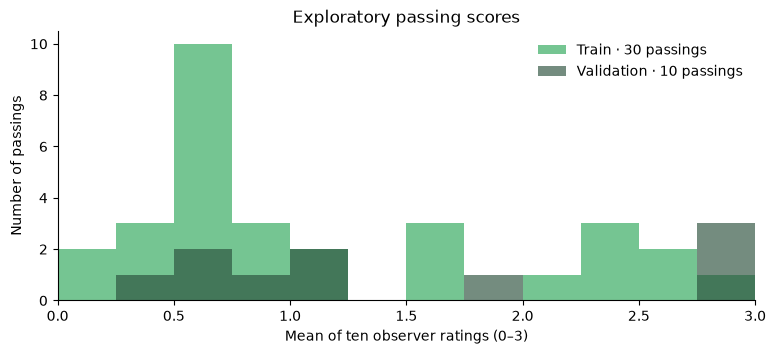

Cow IDs do not overlap between train and validation.


In [2]:
manifest_path = repo / "ml/data/manifests/sydney_candidate_passing_manifest.csv"
split_path = repo / "ml/splits/sydney_passing_split.csv"
for path in [manifest_path, split_path]:
    if not path.exists():
        raise FileNotFoundError(f"Required local file missing: {path}")

# Only bring the two development partitions into this walkthrough.
with manifest_path.open(newline="") as f:
    development = [r for r in csv.DictReader(f) if r["split"] in {"train", "validation"}]
train = [r for r in development if r["split"] == "train"]
validation = [r for r in development if r["split"] == "validation"]
assert train and validation
assert {r["cow_id"] for r in train}.isdisjoint(r["cow_id"] for r in validation)
fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.linspace(0, 3, 13)
ax.hist([float(r["score"]) for r in train], bins=bins, alpha=.8, label=f"Train · {len(train)} passings", color="#52B777")
ax.hist([float(r["score"]) for r in validation], bins=bins, alpha=.65, label=f"Validation · {len(validation)} passings", color="#294E3B")
ax.set(title="Exploratory passing scores", xlabel="Mean of ten observer ratings (0–3)", ylabel="Number of passings", xlim=(0, 3))
ax.legend(frameon=False); plt.show()
print("Cow IDs do not overlap between train and validation.")

## 2. The actual score-only baseline

The model always predicts the **training-set mean**, regardless of the video. This creates a reference point for later work; it is **not** gait detection. The plot uses the previously saved validation predictions and recalculates the metrics from them.

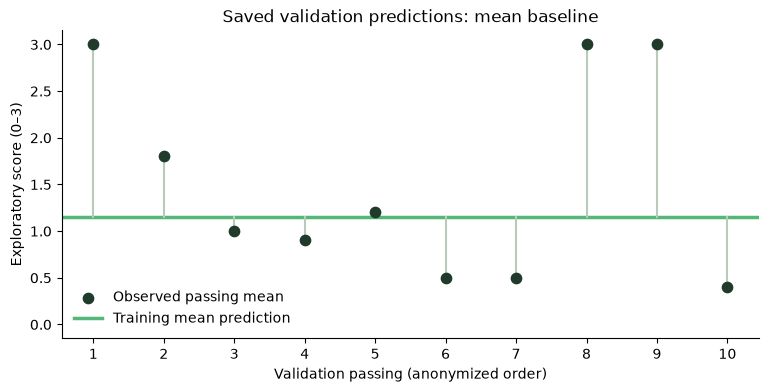

Training mean: 1.147
Validation: 10 passings / 8 cows
MAE: 0.870 | RMSE: 1.105 score units
Each line is one absolute error; this model does not inspect footage.


In [3]:
baseline_dir = repo / "ml/outputs/stage3/mean_validation_recorded"
config_path = baseline_dir / "config.json"
pred_path = baseline_dir / "validation_predictions.csv"
if not config_path.exists() or not pred_path.exists():
    raise FileNotFoundError(f"Saved baseline missing in {baseline_dir}; see ml/docs/STAGE_3_REPORT.md.")
config = json.loads(config_path.read_text())
actual_hash = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
if config["manifest_sha256"] != actual_hash:
    raise ValueError("Manifest differs from the one used for the saved baseline; do not present these results as current.")
with pred_path.open(newline="") as f:
    pred_rows = list(csv.DictReader(f))
assert pred_rows and all(r["split"] == "validation" for r in pred_rows)
truth = [float(r["y_true"]) for r in pred_rows]
pred = [float(r["prediction"]) for r in pred_rows]
metrics = regression_metrics(truth, pred)
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(truth))
ax.scatter(x, truth, label="Observed passing mean", s=55, color="#203A2B", zorder=3)
ax.axhline(config["training_mean"], color="#52B777", linewidth=2.5, label="Training mean prediction")
for xi, observed, predicted in zip(x, truth, pred):
    ax.plot([xi, xi], [observed, predicted], color="#B9C9BB", linewidth=1.5)
ax.set(title="Saved validation predictions: mean baseline", xlabel="Validation passing (anonymized order)", ylabel="Exploratory score (0–3)", ylim=(-.15, 3.15), xticks=x, xticklabels=np.arange(1, len(truth)+1))
ax.legend(frameon=False); plt.show()
print(f"Training mean: {config['training_mean']:.3f}")
print(f"Validation: {metrics['n']} passings / {config['prediction_cow_count']} cows")
print(f"MAE: {metrics['mae']:.3f} | RMSE: {metrics['rmse']:.3f} score units")
print("Each line is one absolute error; this model does not inspect footage.")

## 3. Why real-video training is blocked

Below are five sampled frames from **one training presentation**. The lower black half is removed and the presentation number at the upper right is masked. These samples are for **quality inspection only**—the scored cow has not been reliably localized. Notice the other animals, rails, and changes in visibility. The candidate interval is guarded but not frame-exact.

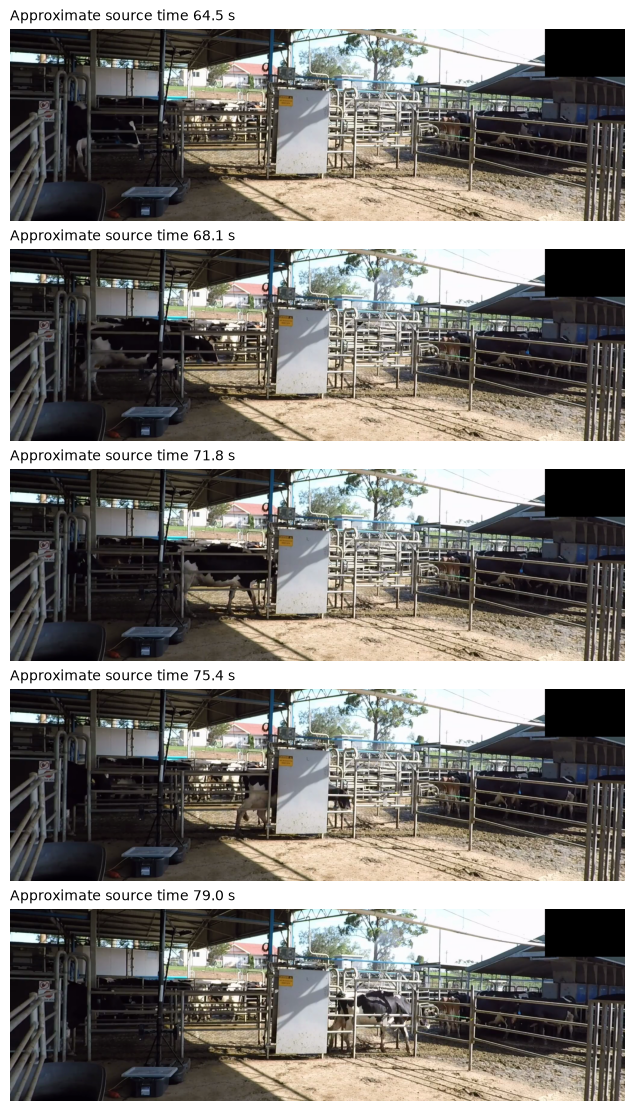

Quality-inspection sample from the training split. The intended cow is not automatically identified.


In [4]:
video_path = repo / "ml/data/sydney/absolute.mp4"
if not video_path.is_file():
    raise FileNotFoundError(f"Sydney video missing: {video_path}")
example = train[0]
start, end = float(example["start_s"]), float(example["end_s"])
times = np.linspace(start, end, 7)[1:-1]
cap = cv2.VideoCapture(str(video_path))
if not cap.isOpened(): raise RuntimeError("Could not open the local Sydney video with OpenCV.")
frames = []
try:
    for t in times:
        cap.set(cv2.CAP_PROP_POS_MSEC, float(t) * 1000)
        ok, bgr = cap.read()
        if not ok or bgr is None: raise RuntimeError(f"Could not decode frame near {t:.2f}s")
        if bgr.shape[:2] != (1280, 2048): raise ValueError(f"Unexpected video dimensions: {bgr.shape}")
        rgb = cv2.cvtColor(bgr[:640, :], cv2.COLOR_BGR2RGB)
        rgb[:160, 1780:] = 0  # Prevent burned-in presentation number from appearing.
        frames.append(rgb)
finally:
    cap.release()
fig, axes = plt.subplots(5, 1, figsize=(13, 11), constrained_layout=True)
for ax, image, time in zip(axes, frames, times):
    ax.imshow(image)
    ax.set_title(f"Approximate source time {time:.1f} s", loc="left", fontsize=10)
    ax.axis("off")
plt.show()
print("Quality-inspection sample from the training split. The intended cow is not automatically identified.")

## 4. Synthetic model-wiring demonstration

This cell feeds **generated random images**, not cattle footage, through the official pretrained ResNet-18 encoder. It averages two frame embeddings per example and fits a small linear head to four invented target values. Fitting and evaluating on the same four inputs deliberately demonstrates overfitting: **the result is a wiring check, not model performance**. The encoder is frozen; no source video or held-out data is used.

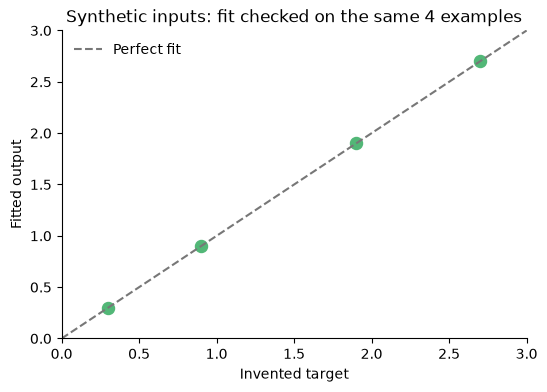

Embedding shape: (4, 512) (4 examples × 512 features)
Synthetic training RMSE: 0.000113
This is a same-data smoke test only; it says nothing about cattle gait or accuracy.


In [5]:
from torchvision.models import resnet18
weights = repo / "ml/data/pretrained/resnet18-f37072fd.pth"
if not weights.is_file():
    raise FileNotFoundError(f"Local ResNet-18 weights missing: {weights}")
torch.set_num_threads(1)
torch.manual_seed(42)
encoder = resnet18(weights=None)
encoder.load_state_dict(torch.load(weights, map_location="cpu", weights_only=True))
encoder.fc = torch.nn.Identity()
encoder.eval()
# These are random tensors, not preprocessed footage.
synthetic_frames = torch.rand((4, 2, 3, 224, 224))
with torch.no_grad():
    embeddings = encoder(synthetic_frames.flatten(0, 1)).reshape(4, 2, -1).mean(dim=1).numpy()
synthetic_truth = [0.3, 0.9, 1.9, 2.7]
head = fit_linear(embeddings, synthetic_truth, embeddings, synthetic_truth,
                  seed=42, epochs=3000, patience=300, learning_rate=0.01)
synthetic_pred = eval_linear(head, embeddings)
smoke = regression_metrics(synthetic_truth, synthetic_pred)
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(synthetic_truth, synthetic_pred, s=75, color="#52B777")
ax.plot([0, 3], [0, 3], "--", color="#777777", label="Perfect fit")
ax.set(title="Synthetic inputs: fit checked on the same 4 examples", xlabel="Invented target", ylabel="Fitted output", xlim=(0, 3), ylim=(0, 3))
ax.legend(frameon=False); plt.show()
print(f"Embedding shape: {embeddings.shape} (4 examples × 512 features)")
print(f"Synthetic training RMSE: {smoke['rmse']:.6f}")
print("This is a same-data smoke test only; it says nothing about cattle gait or accuracy.")

## What remains

- Identify and track the scored cow and determine whether each sampled segment shows sufficient walking.
- Validate timestamp accuracy, frame crops, and overlay masking before enabling real-video feature extraction.
- Run the actual clip overfit test and compare video baselines on training/validation only; lock the method before any test-set evaluation.

See `ml/docs/STAGE_3_REPORT.md` and `ml/docs/STAGE_2_AUDIT.md` for the research and data limitations.